# AI Support Ticket Triage & Quality Review System

**Keisha Walker | Applied machine learning case study**

This executed notebook reproduces a local support-intent routing experiment on the public BANKING77 benchmark, then audits an assistive review workflow. It is not an IT production evaluation, financial-advice system, or autonomous agent. All summary/review fixtures are authored synthetic diagnostics, not external validation.

The notebook retrains both candidates from included data. No API keys or network calls are required after installation.

## 1. Environment and frozen decisions

Python 3.12, seed 42. Word/bigram TF-IDF + logistic regression is the baseline. Word/bigram plus character 3–5-gram TF-IDF + sigmoid-calibrated LinearSVC is the richer candidate. The SVM calibrates with three training-only folds, including fold-local vocabularies. Hyperparameters, the nine-queue taxonomy, and review heuristics are defined before evaluation. Model selection uses validation intent macro-F1, not test results.

In [1]:
import os, sys, json, platform
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
os.environ['MPLCONFIGDIR'] = '/tmp/ticket-triage-mpl'
import pandas as pd
from IPython.display import display, Image
from src.config import INTENT_TO_QUEUE
print('Python:', platform.python_version())
print('Support intents:', len(INTENT_TO_QUEUE), '| operational categories:', len(set(INTENT_TO_QUEUE.values())))

Python: 3.12.14
Support intents: 77 | operational categories: 9


## 2. Data provenance and split hygiene

Source: [PolyAI task-specific-datasets, banking_data](https://github.com/PolyAI-LDN/task-specific-datasets/tree/master/banking_data), CC BY 4.0; pinned commit and hashes are in data/DATA_PROVENANCE.md. The public corpus has 10,003 development rows and 3,080 official test rows. Collection method is not established here as verified production ticket data.

Official test rows and labels are preserved. Test text is consulted for normalized exact-duplicate hygiene, removing overlapping development rows. Conflicting normalized development strings and repeated development rows are removed, then an 80/20 stratified train/validation split is made. This is not a claim that test content was never inspected; no test labels or scores select the model, threshold, taxonomy or rules. Near-duplicate and semantic leakage remain possible.

In [2]:
from src.train import main
metrics = main()
display(pd.DataFrame([metrics['splits']]).T.rename(columns={0:'Value'}))

Fitting: Word TF-IDF logistic regression
Word TF-IDF logistic regression {'validation': {'accuracy': 0.8854271356783919, 'macro_f1': 0.8867118748560555, 'weighted_f1': 0.885354509960072, 'queue_accuracy': 0.9467336683417086, 'queue_macro_f1': 0.9492350713839447, 'log_loss': 0.7741089193401652, 'multiclass_brier_sum': 0.28344300059164235, 'expected_calibration_error_10_bins': 0.27267861497430723, 'mean_confidence': 0.6127485207040849}, 'fit_seconds': 3.8142750609999894}
Fitting: Word + character calibrated SVM
Word + character calibrated SVM {'validation': {'accuracy': 0.8959798994974875, 'macro_f1': 0.8980478055080949, 'weighted_f1': 0.895985303725361, 'queue_accuracy': 0.9472361809045227, 'queue_macro_f1': 0.9483347779649784, 'log_loss': 0.43626381164637035, 'multiclass_brier_sum': 0.15734737209574698, 'expected_calibration_error_10_bins': 0.065474393737159, 'mean_confidence': 0.8442520620620164}, 'fit_seconds': 6.3322639819998585}
Test: Word TF-IDF logistic regression {'accuracy': 0.

,Value
original_development_rows,10003
original_test_rows,3080
development_rows_removed_for_test_overlap,25
development_conflicting_rows_removed,2
development_duplicate_rows_removed,30
test_normalized_duplicate_rows_retained,4
train_rows,7956
validation_rows,1990
test_rows,3080
seed,42


## 3. Compare both candidates

Both test results are reported only after validation selection. Re-runs repair evaluation bookkeeping or documentation, not model choices. Macro-F1 gives equal weight to each of the 77 intent classes. Queue macro-F1 evaluates a separate, project-defined nine-category aggregation and must not replace intent results.

,model,split,macro_f1,accuracy,queue_macro_f1,log_loss,expected_calibration_error_10_bins
0,Word TF-IDF logistic regression,validation,0.8867,0.8854,0.9492,0.7741,0.2727
1,Word TF-IDF logistic regression,test,0.8766,0.8766,0.9464,0.7659,0.2644
2,Word + character calibrated SVM,validation,0.8980,0.8960,0.9483,0.4363,0.0655
3,Word + character calibrated SVM,test,0.9033,0.9032,0.9563,0.3997,0.0583


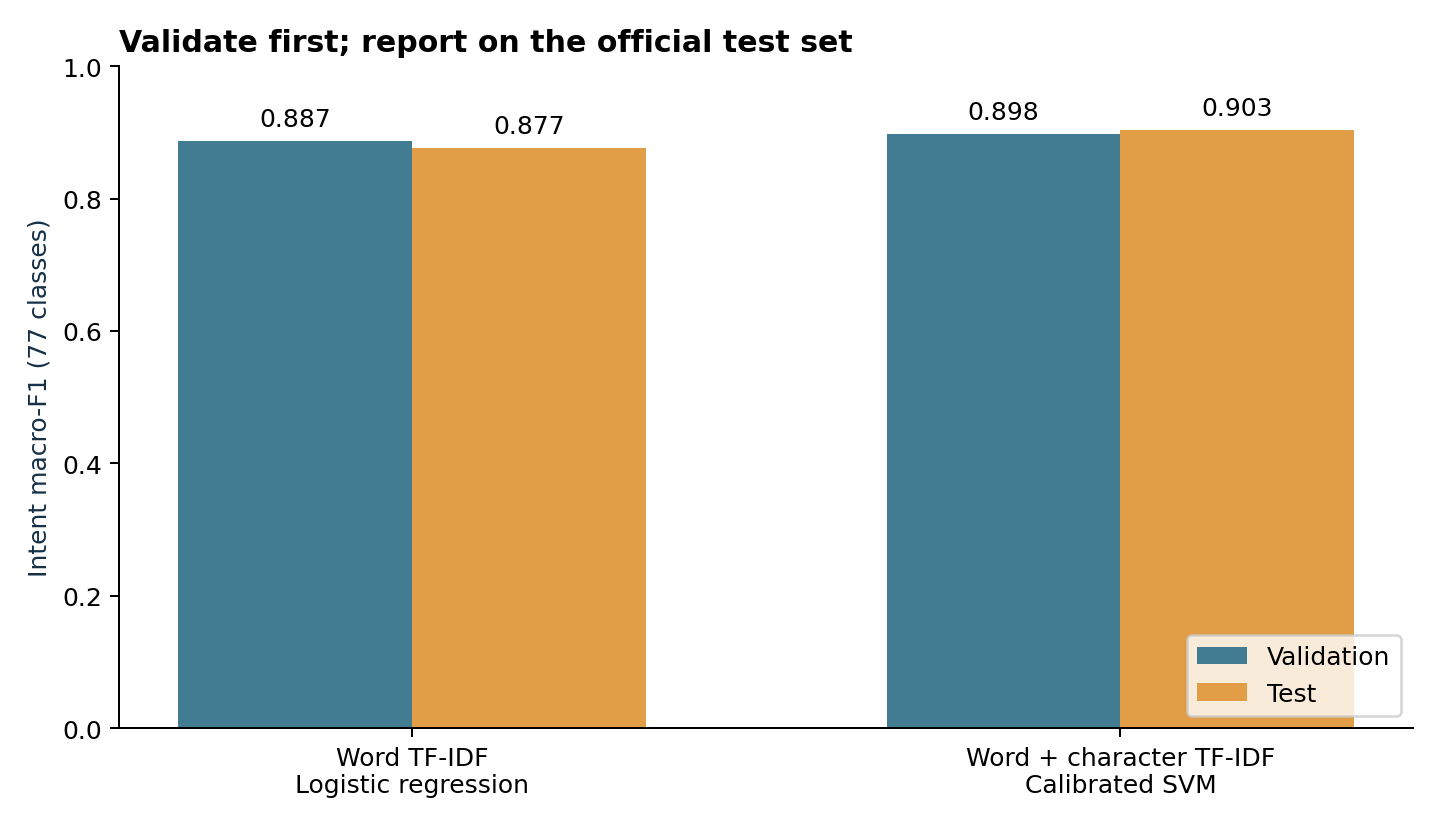

In [3]:
rows = []
for name, record in metrics['models'].items():
    for split in ['validation', 'test']:
        rows.append({'model': name, 'split': split, **record[split]})
comparison = pd.DataFrame(rows)
display(comparison[['model','split','macro_f1','accuracy','queue_macro_f1','log_loss','expected_calibration_error_10_bins']].round(4))
display(Image(filename=str(ROOT / 'reports/figures/model_comparison.png')))

## 4. Calibration and threshold selection

The confidence threshold is chosen from a 0.01 grid to maximize validation coverage while observed validation error is at most 5% and at least 100 predictions are accepted. This empirical target is not a guarantee. Confidence means estimated probability of the fine-grained intent, not the broad routing category. Top-label ECE uses 10 fixed-width bins. Wilson intervals summarize conditional test error but do not prove production reliability.

Selected model: Word + character calibrated SVM
Validation-selected threshold: 0.57


,validation_score_only,test_score_only
threshold,0.570000,0.570000
accepted,1797.000000,2788.000000
coverage,0.903015,0.905195
errors,88.000000,140.000000
error_rate,0.048971,0.050215
error_ci_low,0.039919,0.042709
error_ci_high,0.059946,0.058959


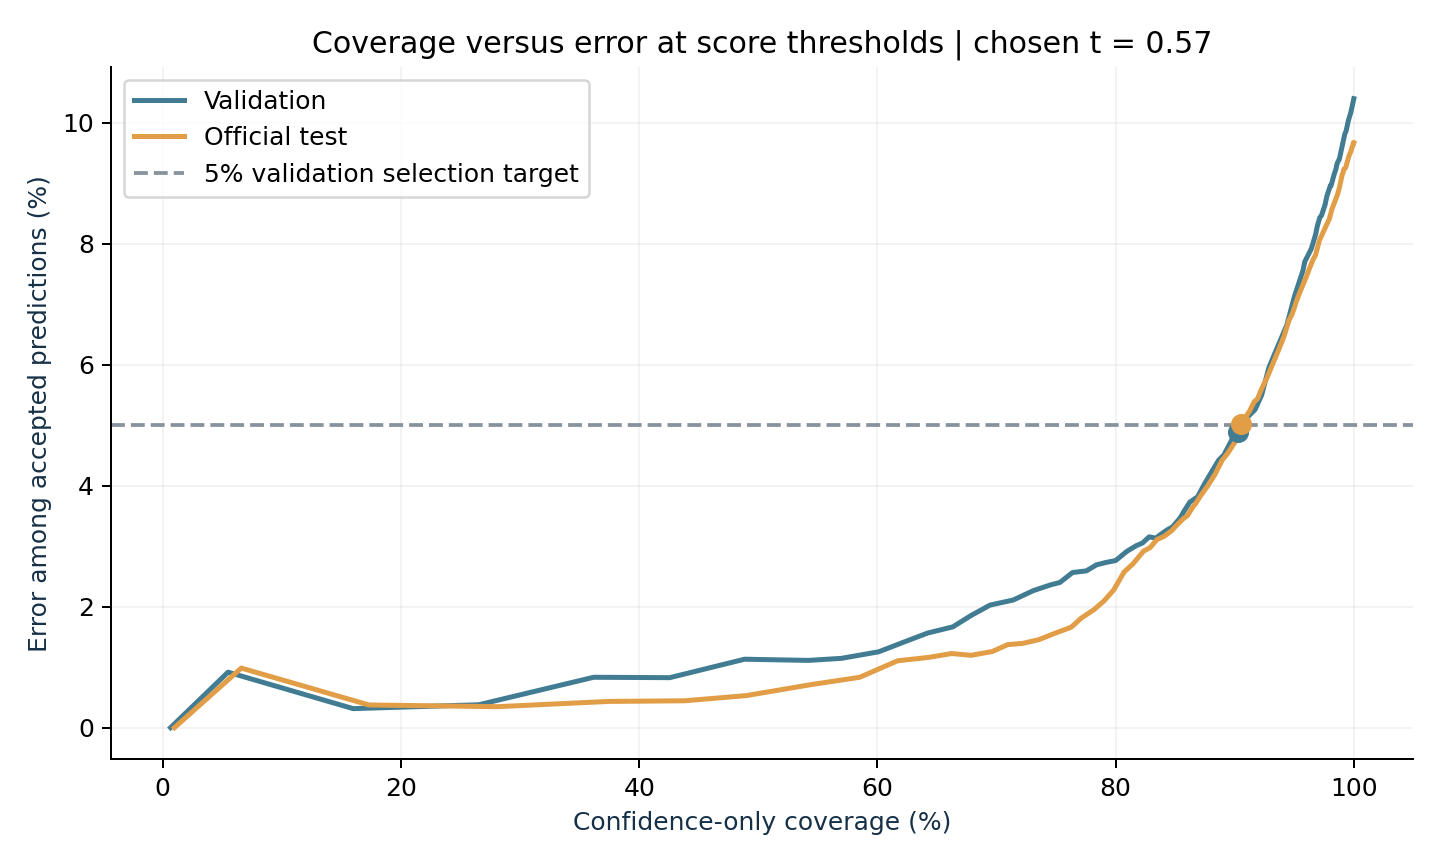

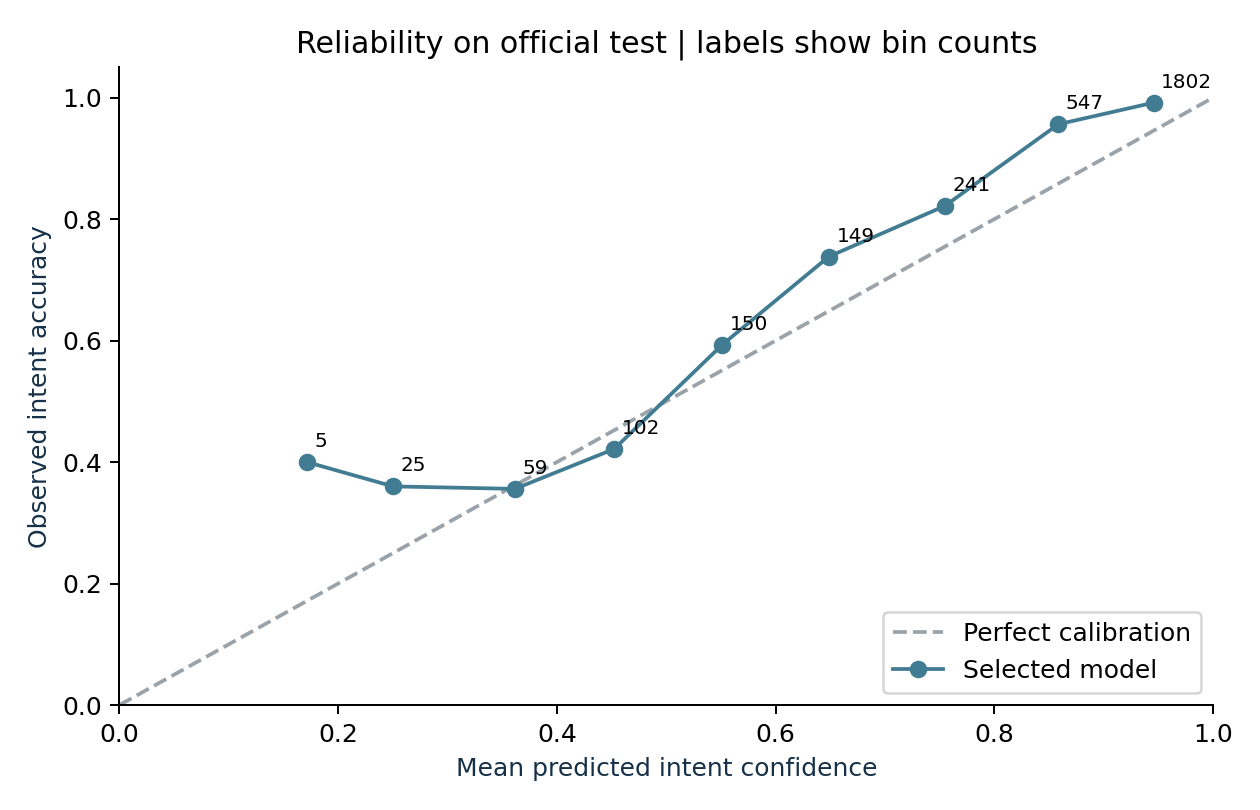

In [4]:
policy = metrics['policy']
print('Selected model:', metrics['selected_model'])
print('Validation-selected threshold:', policy['threshold'])
display(pd.DataFrame({'validation_score_only':policy['validation_score_only'], 'test_score_only':policy['test_score_only']}))
display(Image(filename=str(ROOT / 'reports/figures/coverage_error.png')))
display(Image(filename=str(ROOT / 'reports/figures/calibration.png')))

## 5. The actual application adds review rules

The app flags low confidence, close top-two intents, weak domain vocabulary, very short inputs, multiple-issue cues, security/dispute topics and summary truncation. Those rules reduce accepted coverage. They are workflow checks, not a calibrated out-of-domain detector and not proof of lower error. All final routing and resolution remain human decisions.

In [5]:
print(json.dumps(policy['test_full_review_policy'], indent=2))
from src.triage import TriageEngine
engine = TriageEngine()
example = 'My card has not arrived after two weeks. Can you check the delivery date?'
display(engine.predict(example))

{
  "accepted": 2152,
  "coverage": 0.6987012987012987,
  "errors": 115,
  "error_rate": 0.05343866171003717,
  "error_wilson_95": [
    0.04470710855458379,
    0.06376171401568297
  ]
}


{'suggested_category': 'Card lifecycle',
 'suggested_intent': 'card_arrival',
 'confidence': 0.5443018199512346,
 'confidence_definition': 'Estimated probability of the suggested intent, not of the broad category; not a correctness guarantee',
 'threshold': 0.57,
 'top_two_margin': 0.21364997419358006,
 'summary': 'My card has not arrived after two weeks. Can you check the delivery date?',
 'summary_method': 'rule-based extractive',
 'summary_truncated': False,
 'human_review': True,
 'review_reasons': ['Confidence below validation-selected threshold'],
 'alternatives': [{'intent': 'card_arrival',
   'probability': 0.5443018199512346},
  {'intent': 'card_delivery_estimate', 'probability': 0.33065184575765455},
  {'intent': 'transfer_not_received_by_recipient',
   'probability': 0.07957784401617056}],
 'scope': 'BANKING77 English support-intent demonstration only; no account or financial actions'}

## 6. Errors and uncertainty

The paired bootstrap resamples official test rows 500 times. Its interval is conditional on this benchmark, not a statement about future service desks. The fixed test includes normalized duplicate rows and similar paraphrases. The most frequent confusions and every per-class score are saved to CSV.

{'replicates': 500,
 'seed': 42,
 'selected_model_macro_f1_percentile_95': [0.8920521412079028,
  0.9119824636782111],
 'candidate_minus_baseline_macro_f1_percentile_95': [0.018477299989011677,
  0.03525013831996761],
 'caveat': 'Paired row bootstrap on this fixed benchmark; does not capture domain shift, training variability or correlated paraphrases.'}

,precision,recall,f1-score,support
top_up_failed,0.750000,0.750,0.750000,40.0
balance_not_updated_after_bank_transfer,0.756098,0.775,0.765432,40.0
card_payment_not_recognised,0.848485,0.700,0.767123,40.0
pending_transfer,0.775000,0.775,0.775000,40.0
failed_transfer,0.750000,0.825,0.785714,40.0
card_not_working,0.729167,0.875,0.795455,40.0
transfer_not_received_by_recipient,0.790698,0.850,0.819277,40.0
top_up_reverted,0.864865,0.800,0.831169,40.0
topping_up_by_card,0.846154,0.825,0.835443,40.0
unable_to_verify_identity,0.813953,0.875,0.843373,40.0


,text,intent,predicted_intent,confidence
0,how many transactions can i make with a dispos...,get_disposable_virtual_card,disposable_card_limits,0.974136
1,can I have a non virtual card?,order_physical_card,getting_virtual_card,0.972572
2,Where do I find the exchange rate?,exchange_charge,exchange_rate,0.951223
3,how long dies it take for transfers to reflect...,transfer_timing,balance_not_updated_after_bank_transfer,0.949154
4,"I was double charged, and the second charge is...",pending_card_payment,transaction_charged_twice,0.943289
5,My transfer is pending.,balance_not_updated_after_bank_transfer,pending_transfer,0.935547
6,What countries can I travel to and have access...,fiat_currency_support,country_support,0.927325
7,Does it cost to exchange currencies with this ...,exchange_charge,exchange_via_app,0.924726


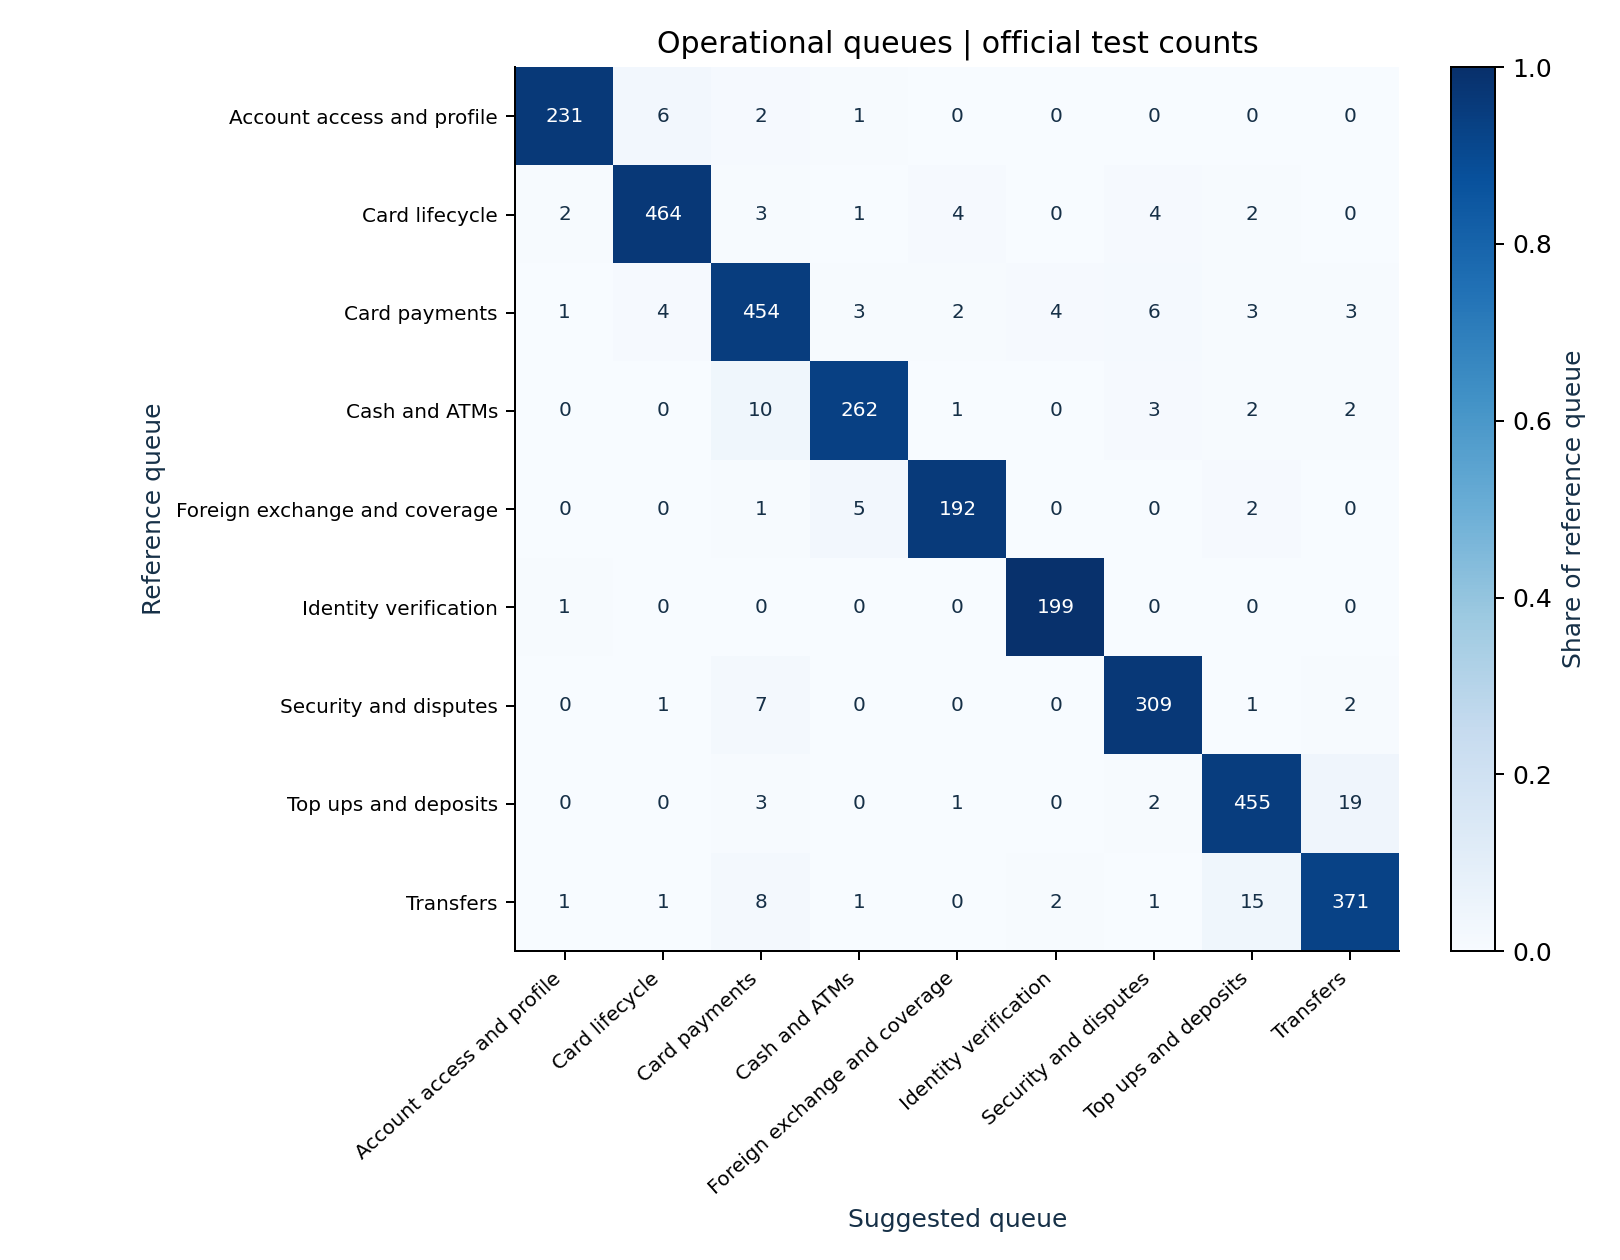

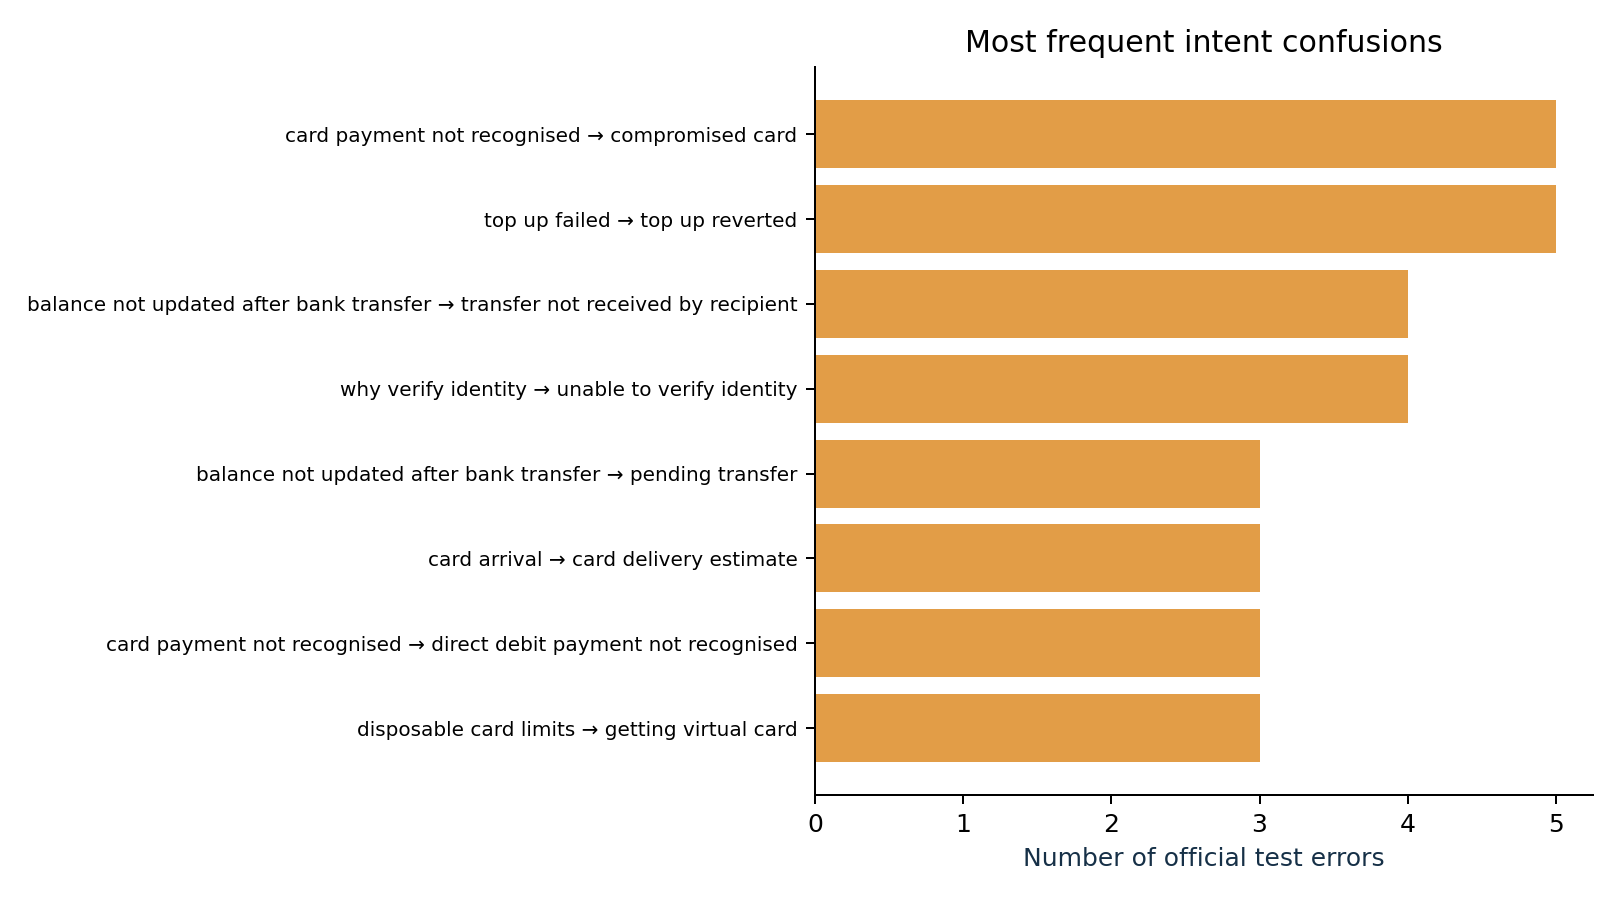

In [6]:
display(metrics['bootstrap'])
display(pd.read_csv(ROOT/'reports/candidate_per_class.csv',index_col=0).loc[list(INTENT_TO_QUEUE)].sort_values('f1-score').head(12))
display(pd.read_csv(ROOT/'reports/error_analysis.csv')[['text','intent','predicted_intent','confidence']].head(8))
display(Image(filename=str(ROOT/'reports/figures/queue_confusion.png')))
display(Image(filename=str(ROOT/'reports/figures/top_confusions.png')))

## 7. Summary and review diagnostics

The summary is not generated: it selects up to two source sentences using fixed issue/domain cue scores, preserves their order, and caps at 60 words. A lead-two-sentences baseline is included. The 36 synthetic messages and 99 expected phrases were authored independently before inference; these scripted expectations are not human judgements. Exact phrase retention and fully extractive output do not establish semantic quality. The 24 review challenges were also held out from tuning, but are still a small project-authored diagnostic set.

In [7]:
from src.evaluate_workflow import evaluate
workflow = evaluate()
display(pd.DataFrame(workflow['summary']).T)
display(pd.DataFrame(workflow['review_challenges']).T)
summary_rows=pd.read_csv(ROOT/'reports/summary_diagnostics.csv')
display(summary_rows[(summary_rows.method=='issue_focused') & ~summary_rows.all_key_phrases_retained][['id','summary','missing_phrases']].head(6))
review_rows=pd.read_csv(ROOT/'reports/review_diagnostics.csv')
display(review_rows[~review_rows.matches_expectation][['text','kind','expected_review','actual_review','confidence']])

{
  "summary": {
    "issue_focused": {
      "fixtures": 36,
      "matched_key_phrases": 82,
      "total_key_phrases": 99,
      "micro_key_phrase_recall": 0.8282828282828283,
      "complete_key_phrase_retention": 0.5277777777777778,
      "fully_extractive_summary_rate": 1.0,
      "mean_summary_to_input_word_ratio": 0.5757774526905552
    },
    "lead_two": {
      "fixtures": 36,
      "matched_key_phrases": 51,
      "total_key_phrases": 99,
      "micro_key_phrase_recall": 0.5151515151515151,
      "complete_key_phrase_retention": 0.19444444444444445,
      "fully_extractive_summary_rate": 1.0,
      "mean_summary_to_input_word_ratio": 0.5173445351978833
    }
  },
  "review_challenges": {
    "ambiguous_multiple_issues": {
      "examples": 8,
      "flagged_for_review": 5,
      "matches_authored_expectation": 5
    },
    "in_domain_straightforward": {
      "examples": 8,
      "flagged_for_review": 1,
      "matches_authored_expectation": 7
    },
    "off_domain": {
    

,fixtures,matched_key_phrases,total_key_phrases,micro_key_phrase_recall,complete_key_phrase_retention,fully_extractive_summary_rate,mean_summary_to_input_word_ratio
issue_focused,36.0,82.0,99.0,0.828283,0.527778,1.0,0.575777
lead_two,36.0,51.0,99.0,0.515152,0.194444,1.0,0.517345


,examples,flagged_for_review,matches_authored_expectation
ambiguous_multiple_issues,8,5,5
in_domain_straightforward,8,1,7
off_domain,8,7,7


,id,summary,missing_phrases
11,summary_006,"Contactless payments fail on my card, but inse...",three different shops
13,summary_007,It is still pending and the recipient details ...,cancel the transfer
17,summary_009,The refund is not showing in my account. I am ...,issued my refund last week
21,summary_011,"I want to change my card PIN, not reset my app...",still know the current PIN
29,summary_015,A card top-up is still pending after two days....,bank has already debited the money
31,summary_016,I received less cash than I requested from the...,debited for the full requested amount


,text,kind,expected_review,actual_review,confidence
1,I lost my bank card yesterday. Please help me ...,in_domain_straightforward,False,True,0.851048
15,My graphics card is not working after a comput...,off_domain,True,False,0.867757
18,My bank card is missing and my incoming bank t...,ambiguous_multiple_issues,True,False,0.922606
21,"How do I get a disposable virtual card, and ho...",ambiguous_multiple_issues,True,False,0.881525
23,"The app says it is blocked, but I cannot work ...",ambiguous_multiple_issues,True,False,0.631086


## 8. Reproduce, inspect and use cautiously

Run `python -m pytest -q` to verify split hygiene, saved metrics, inference, masking, extraction and Streamlit interaction. Run `streamlit run app.py` for the local demo. Models are persisted with joblib; never load untrusted pickle/joblib files.

Known failures include off-domain phrases with banking-like words, multi-issue messages without cue words, omitted summary details and overconfident mistakes. Independent exploratory probes such as “My graphics card is not working” can pass the review rules. No rules were retuned on those probes. No production deployment, real-world IT validation, human summary study or time-savings study is claimed.

Next step: obtain an authorized, de-identified target-domain dataset; agree on the queue taxonomy and review cost; perform time-based and site-based validation; run a blinded human summary study; then test in shadow mode with audit logging and no automatic account actions.